# 07 · 第四课：第一次云 GPU SFT（AutoDL）

上一课，我们让随机小模型预测书籍的下一个 token；这一课从**真实 Qwen3-4B 的已有权重**开始，学习按用户要求输出结构化答案。

任务是采购信息抽取：读一段文本，只输出 `product、quantity、unit、delivery_city` 四个字段的 JSON。这样能检查格式和字段正确性，不凭感觉说“微调后更好了”。

SFT 是训练任务与目标；LoRA 是更新参数的方式。本课提供全参数、LoRA 两种配置；先用 LoRA 做两步 CUDA 试跑，再决定正式实验。你已有 AutoDL 账户，云端操作直接看 [CLOUD_RUN.md](CLOUD_RUN.md)。本 Notebook 可在本机先读，不会自动租卡、创建实例或执行云训练。

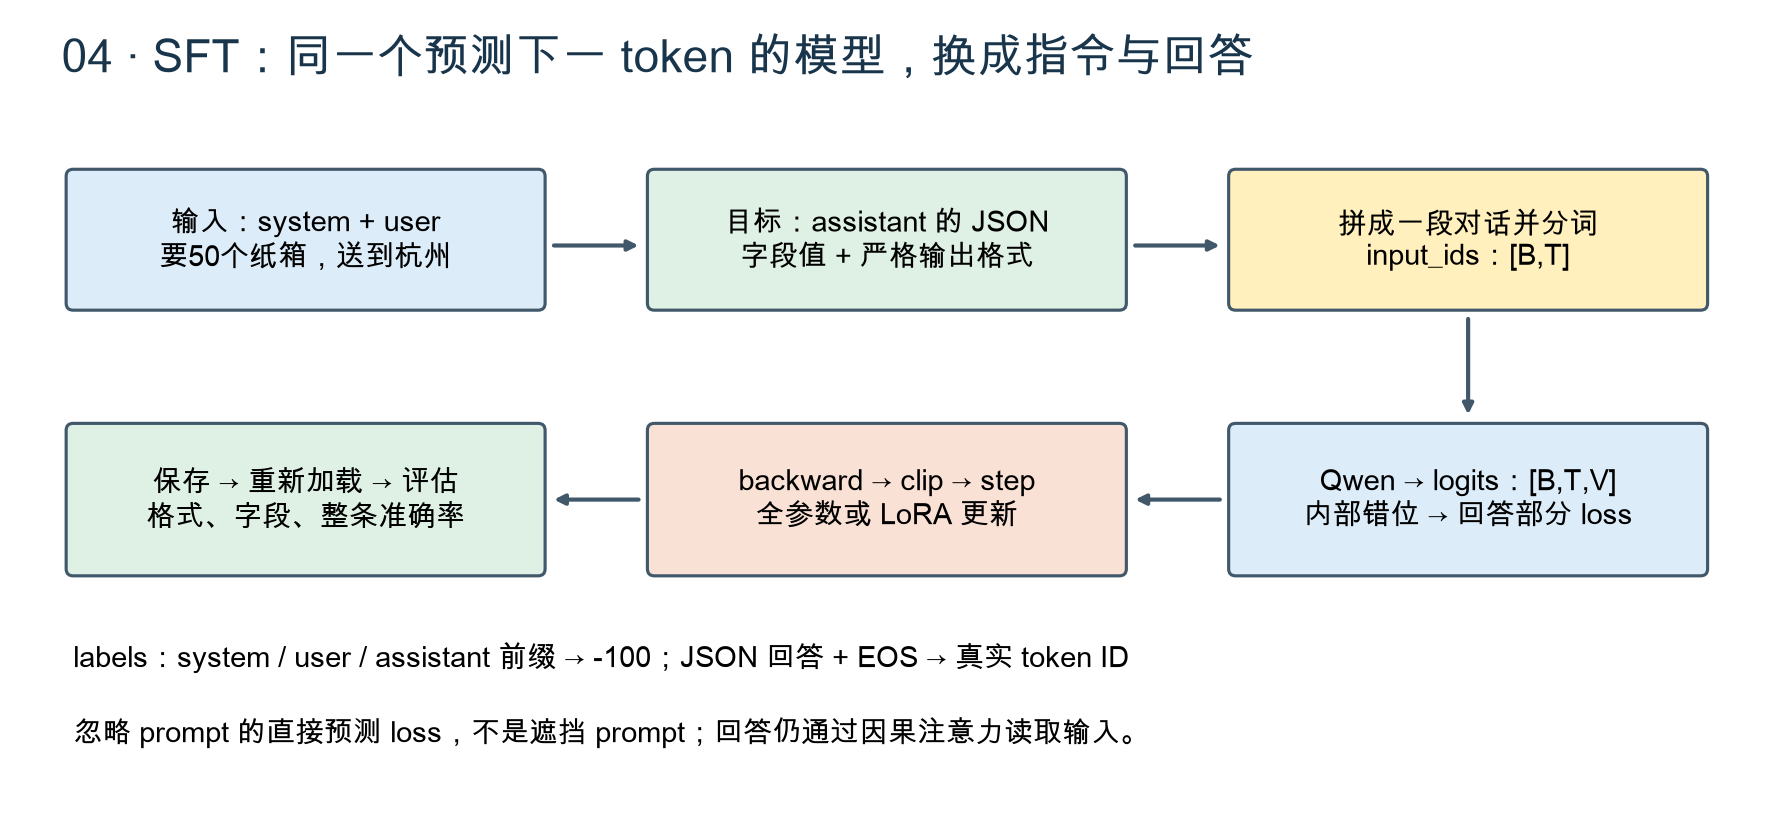

## 1 · 先看一条完整的输入与目标

本机仓库根目录运行 `uv sync --extra sft`，选择项目 `.venv` 内核。云端使用独立的 requirements-cloud.txt，复用镜像的 CUDA PyTorch，不复制 Mac 环境。

本课全部数据是固定随机种子生成的合成教学样本，没有真实客户信息。160 条训练、32 条验证、32 条测试。先分配原始场景再做两种改写，组间不交叉；验证/测试还使用不同句式。它能验证训练和评估方法，不能代表真实业务效果。

In [1]:
from pathlib import Path
import sys, json
# 同时兼容本仓库和上传后的独立 cloud-sft 包。
candidates = [Path.cwd(), Path.cwd()/'07-modern-llm'/'04-cloud-sft']
LESSON = next(p for p in candidates if (p/'sft_data.py').is_file())
sys.path.insert(0,str(LESSON))
from sft_data import read_rows, encode_row, collate, prompt_messages, score, MODEL_ID, REVISION, tokenizer_for
import torch

tokenizer = tokenizer_for()
row = read_rows('train')[2]
print('来源:',row['origin'],'| 分组:',row['group_id'])
print('输入:',row['text'])
print('期望回答:',json.dumps(row['answer'],ensure_ascii=False))
print('划分:',{name:len(read_rows(name)) for name in ['train','validation','test']})

来源: synthetic | 分组: train-001
输入: 采购记录：帆布袋；1567个；送到厦门。
期望回答: {"product": "帆布袋", "quantity": 1567, "unit": "个", "delivery_city": "厦门"}
划分: {'train': 160, 'validation': 32, 'test': 32}


## 2 · 从 messages 到 labels：只监督回答

SFT 样本并不只有用户问题，还包含一个期望回答。训练时它们一起进入模型，causal mask 阻止某个位置看到未来答案；模型内部自动把 logits 与下一 token 对齐。

本课采用非思考模式。Qwen 模板插入的空 `<think>` 段属于 assistant 生成前缀，也被设为 `-100`；JSON 正文和 `<|im_end|>` 是有效目标。这里没有训练思维链，也没有把“非思考模式”当作删除网络层。

**loss mask 和 attention mask 不同**：prompt 虽然不直接计入 loss，仍然作为回答的上下文参与计算，相关参数仍可能收到梯度。

In [2]:
encoded = encode_row(tokenizer,row)
n = encoded['prompt_length']
print('完整模型输入：\n',tokenizer.decode(encoded['input_ids']))
print('\n不直接计算loss的前缀：\n',tokenizer.decode(encoded['input_ids'][:n]))
print('\n真正参与loss的目标：\n',tokenizer.decode([x for x in encoded['labels'] if x!=-100]))
print('总token:',len(encoded['input_ids']),'| prompt:',n,'| 回答+EOS:',len(encoded['input_ids'])-n)
print('\n回答边界附近：位置、token、label')
for i in range(n-3,min(n+12,len(encoded['input_ids']))):
    print(i,repr(tokenizer.convert_ids_to_tokens(encoded['input_ids'][i])),encoded['labels'][i])
assert encoded['labels'][:n] == [-100]*n
assert encoded['labels'][-1] == tokenizer.eos_token_id

完整模型输入：
 <|im_start|>system
你是采购信息抽取助手。只输出一个JSON对象，不要解释或Markdown。字段严格为product、quantity、unit、delivery_city。product和delivery_city为字符串或null，quantity为整数或null，unit为字符串或null。提取最终确认的采购需求，忽略库存和历史订单；未明确给出的字段填null，不要推测。<|im_end|>
<|im_start|>user
采购记录：帆布袋；1567个；送到厦门。<|im_end|>
<|im_start|>assistant
<think>

</think>

{"product":"帆布袋","quantity":1567,"unit":"个","delivery_city":"厦门"}<|im_end|>

不直接计算loss的前缀：
 <|im_start|>system
你是采购信息抽取助手。只输出一个JSON对象，不要解释或Markdown。字段严格为product、quantity、unit、delivery_city。product和delivery_city为字符串或null，quantity为整数或null，unit为字符串或null。提取最终确认的采购需求，忽略库存和历史订单；未明确给出的字段填null，不要推测。<|im_end|>
<|im_start|>user
采购记录：帆布袋；1567个；送到厦门。<|im_end|>
<|im_start|>assistant
<think>

</think>



真正参与loss的目标：
 {"product":"帆布袋","quantity":1567,"unit":"个","delivery_city":"厦门"}<|im_end|>
总token: 132 | prompt: 108 | 回答+EOS: 24

回答边界附近：位置、token、label
105 'ĊĊ' -100
106 '</think>' -100
107 'ĊĊ' -100
108 '{"' 4913
109 'product' 3031
110 '":"' 3252
111 'å¸Ĩ' 106414
112 'å¸ĥ' 51827
113 'è¢ĭ' 100509

第一个回答 token 的目标，实际由前缀最后一个位置的 logits 预测。我们把 labels 的前 n 个位置设为 -100，模型内部右移对齐后，恰好保留这个预测任务；不要再手动移动 labels。

`encode_row` 用完整模板得到真实 token 边界，并验证生成前缀完全一致；超过 max_length 会拒绝样本。静默截断可能留下半个 JSON，甚至没有任何有效回答 token。

组 batch 时，仅在右侧添加 PAD，PAD 的 attention_mask 为 0、label 为 -100。模型的因果 mask 仍然存在。

In [3]:
examples=[encode_row(tokenizer,r) for r in read_rows('train')[:8]]
batch=collate(examples,tokenizer.pad_token_id)
print({k:tuple(v.shape) for k,v in batch.items()})
print('每条有效回答目标数:',batch['labels'][:,1:].ne(-100).sum(dim=1).tolist())
print('padding 都被排除出loss:',bool((batch['labels'][batch['attention_mask']==0]==-100).all()))

{'input_ids': (8, 145), 'labels': (8, 145), 'attention_mask': (8, 145)}
每条有效回答目标数: [19, 19, 24, 24, 23, 23, 22, 22]
padding 都被排除出loss: True


## 3 · SFT 与 LoRA 各改变什么

| 项目 | 全参数 SFT | LoRA SFT |
|---|---|---|
| 输入、labels、交叉熵 | 相同 | 相同 |
| 原始模型权重 | 更新 | 冻结 |
| 新增矩阵 A/B | 无 | 更新 |
| 保存的推理权重 | 完整模型 | adapter，需要原始基座一起使用 |

配置为 rank=16、alpha=32，普通 LoRA 的缩放为 alpha/r=2；作用于 Attention 和 FFN 的七类线性层。Embedding 和 LM head 没有被设为 LoRA 目标，保持冻结。总可训练参数会在训练启动时打印，不把“可训练参数减少”直接换算成等比例显存或时间减少。

```python
model = get_peft_model(base_model, LoraConfig(
    r=16, lora_alpha=32, lora_dropout=0.0,
    target_modules=['q_proj','k_proj','v_proj','o_proj',
                    'gate_proj','up_proj','down_proj'],
    bias='none', task_type='CAUSAL_LM',
))
```

`configs/full.json` 与 `configs/lora.json` 都提供了完整配置。第一次不是比较方法优劣的严谨消融：两种配置学习率不同，且云端资源尚需实测。

## 4 · 训练循环没有换一个学习原理

仍然执行前向、回答部分交叉熵、反向传播、梯度裁剪和 Adam 更新。LoRA 微批量 4、累积 4 次；全参数微批量 1、累积 16 次，单卡有效 batch 均为 16。

本课按每个 micro-batch 的有效回答 token 数加权，再累积梯度，避免短答案与长答案被错误地赋予相同整批权重。loss 忽略用户部分，计时里的 `answer_tokens_per_second` 也只统计有效目标，不能冒充全部输入 token 吞吐。

梯度检查点（gradient checkpointing）用重算部分激活节省显存；它与保存训练 checkpoint、推理 KV cache 是三个不同概念。训练时 `use_cache=False`；没有启用多卡或量化。

In [4]:
import inspect
from run import update
print(inspect.getsource(update))

def update(model,optimizer,batches):
    """按有效回答 token 总数加权；不是简单平均不同长度 micro-batch 的 loss。"""
    optimizer.zero_grad(set_to_none=True)
    n_total=sum(int(b['labels'][:,1:].ne(-100).sum()) for b in batches)
    loss_sum=0.
    for batch in batches:
        n=int(batch['labels'][:,1:].ne(-100).sum())
        with forward_context(model):
            out=model(**batch,use_cache=False)
        (out.loss*(n/n_total)).backward()
        loss_sum+=out.loss.detach().float().item()*n
    norm=torch.nn.utils.clip_grad_norm_(model.parameters(),1.0,error_if_nonfinite=True,foreach=False)
    optimizer.step()
    return loss_sum/n_total,float(norm),n_total



## 5 · 评价不只看“能不能输出 JSON”

我们采用严格评分，不替模型自动剥离 Markdown 或修补 JSON：

- JSON 合法率：整段输出是否是合法 JSON；重复 key、NaN 等被拒绝。
- Schema 合规率：必须是规定的四个字段，类型正确，没有额外字段。
- 字段准确率：所有样本四个字段分别计分；缺失字段与解析失败不能从分母里消失。
- 整条准确率：schema 正确且四个字段都与目标完全一致。

`2`、`"2"`、`true` 不等价；`null` 与字符串 `"null"` 不等价。不同句式和原始场景在划分时隔离，但所有数据仍是合成的；真实业务需要额外数据与评测。

In [5]:
target={'product':'纸箱','quantity':50,'unit':'个','delivery_city':'杭州'}
outputs=[json.dumps(target,ensure_ascii=False),
         json.dumps({**target,'quantity':'50'},ensure_ascii=False),
         '```json\n'+json.dumps(target,ensure_ascii=False)+'\n```',
         json.dumps({**target,'quantity':100},ensure_ascii=False)]
for text in outputs:
    print(repr(text),'→',score(text,target))

'{"product": "纸箱", "quantity": 50, "unit": "个", "delivery_city": "杭州"}' → {'json_valid': True, 'schema_valid': True, 'exact': True, 'correct_fields': 4}
'{"product": "纸箱", "quantity": "50", "unit": "个", "delivery_city": "杭州"}' → {'json_valid': True, 'schema_valid': False, 'exact': False, 'correct_fields': 3}
'```json\n{"product": "纸箱", "quantity": 50, "unit": "个", "delivery_city": "杭州"}\n```' → {'json_valid': False, 'schema_valid': False, 'exact': False, 'correct_fields': 0}
'{"product": "纸箱", "quantity": 100, "unit": "个", "delivery_city": "杭州"}' → {'json_valid': True, 'schema_valid': True, 'exact': False, 'correct_fields': 3}


## 6 · 本地与 A800 分别验证了什么？

当前配置为 Qwen3-4B + 单张 A800 80GB。下面分别读取两份验证报告：`assets/local-verification.json` 记录本地真实 tokenizer 与小随机模型算法检查；可选的 `assets/a800-verification.json` 记录 A800 上实际执行的环境检查、训练、保存重载与评估，具体完成范围以报告内容为准。报告缺失时只显示未执行或未记录，不预写实验结果。

旧版 0.6B MPS 实验单独归档到 assets/history-qwen3-0.6b，不是当前模型的结果。

LoRA 使用 BF16 基座；全参数保留 FP32 权重和 Adam，BF16 混合精度计算。均开启梯度检查点。全参数恢复 checkpoint 约 45 GiB，先检查数据盘空间。

In [6]:
reports=[
    ('本地检查：真实 tokenizer 与小随机模型算法', 'local-verification.json'),
    ('A800 实测：云端环境、训练、保存重载与评估；完成项以报告为准', 'a800-verification.json'),
]
for scope,filename in reports:
    report_path=LESSON/'assets'/filename
    print()
    print(scope)
    print('报告文件:',report_path)
    if report_path.exists():
        print(report_path.read_text())
    else:
        print('未执行或尚未记录：当前没有这份验证报告。')


本地检查：真实 tokenizer 与小随机模型算法
报告文件: /Users/yorkchen/文稿 - 陈尧的MacBook Pro/VibeCoding/llm-from-zero/07-modern-llm/04-cloud-sft/assets/local-verification.json
{
  "model_id": "Qwen/Qwen3-4B",
  "revision": "1cfa9a7208912126459214e8b04321603b3df60c",
  "target_device": "A800 80GB × 1",
  "tokenizer_check": "224 samples; max_length=146; no truncation",
  "tests": "9 tests: real tokenizer, tiny random models, mocked hardware guards, offline tokenizer regression",
  "cuda_status": "not run",
  "weights_downloaded": false,
  "historical_results": "history-qwen3-0.6b/; not results for 4B",
  "config_source": "https://huggingface.co/Qwen/Qwen3-4B/blob/1cfa9a7208912126459214e8b04321603b3df60c/config.json"
}


A800 实测：云端环境、训练、保存重载与评估；完成项以报告为准
报告文件: /Users/yorkchen/文稿 - 陈尧的MacBook Pro/VibeCoding/llm-from-zero/07-modern-llm/04-cloud-sft/assets/a800-verification.json
{
  "model_id": "Qwen/Qwen3-4B",
  "revision": "1cfa9a7208912126459214e8b04321603b3df60c",
  "gpu": "NVIDIA A800-SXM4-80GB",
  "torch": "2

## 7 · 到 AutoDL 跑：先试 2 步，再跑 60 步

详细的选卡、上传、环境、费用、TensorBoard、恢复与下载步骤见 [CLOUD_RUN.md](CLOUD_RUN.md)。上传包是 `dist/autodl-sft-qwen3-4b-a800.zip`；模型权重首次在云端下载到数据盘缓存。

使用单张 A800 80GB GPU和 CUDA 可用的 PyTorch 镜像。价格看当时控制台，不在课件里伪造固定单价。运行 `doctor --device cuda`，确认显存和软件版本，再试跑。所有 CUDA 命令在云端终端运行，不要在 Mac 上直接运行。

```bash
python run.py doctor --device cuda
python run.py inspect
python run.py eval --device cuda --split validation --limit 8 --out runs/before-validation8.json
python run.py train --device cuda --config configs/lora.json --steps 2 --out runs/lora-trial
```

查看试跑的 peak_allocated_gib、update_seconds、训练/验证 loss、checkpoint 是否完整，再决定正式配置。先用验证集选择，确定后保留测试集训练前结果：

```bash
python run.py eval --device cuda --split test --out runs/before-test.json
python run.py train --device cuda --config configs/lora.json --out runs/lora-60
python run.py eval --device cuda --split test --checkpoint runs/lora-60/checkpoint-000060 --out runs/after-test.json
python run.py compare --before runs/before-test.json --after runs/after-test.json --out runs/test-comparison.json
```

`train` 会拒绝已有输出目录，避免覆盖旧结果；恢复使用 `--resume`。推理时要加载 adapter 加基座，只重新加载原始 MODEL_ID 不会包含训练成果。

## 8 · 完成这一轮的标准

拿到四类产物：训练配置与环境记录、训练日志与验证曲线、可重新加载的权重、固定测试题上的逐条预测与评分。它们比一句“loss 下降了”更能说明实验发生了什么。

训练恢复文件包含 Adam 状态、步数、CPU/CUDA 随机状态、抽样器状态和数据哈希；不保证跨设备逐位一致。先用保存后的 checkpoint 在云端重载做推理，再下载结果包。确认下载成功后关闭实例；关机不一定终止付费扩容存储计费，释放前确认备份。

本轮不要求模型一定变强，不安排 homework。云端跑通后，再讨论全参数/LoRA 的资源差异、更多真实样本、DPO 与 RL。官方参考：[Qwen3-4B](https://huggingface.co/Qwen/Qwen3-4B)、[PEFT 配置与模型](https://huggingface.co/docs/peft/guides/peft_model_config)、[AutoDL 指南](CLOUD_RUN.md)。